<a href="https://colab.research.google.com/github/marielaAriass/MAT_TDA_YEAST/blob/main/scripts/cortes_matrices_fasta.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Librerias

In [30]:
import os
import pandas as pd
import zipfile
import subprocess
import seaborn as sns
import matplotlib.pyplot as plt

## Descomprimir

In [ ]:
!unzip CORRECTO.zip

Archive:  CORRECTO.zip
   creating: CORRECTO/
   creating: CORRECTO/CHR3/
  inflating: CORRECTO/CHR3/chr3_ADE.fna  
  inflating: CORRECTO/CHR3/chr3_ADI.fna  
  inflating: CORRECTO/CHR3/chr3_AHG.fna  
  inflating: CORRECTO/CHR3/chr3_AHL.fna  
  inflating: CORRECTO/CHR3/chr3_AIE.fna  
  inflating: CORRECTO/CHR3/chr3_ALI_HP1.fna  
  inflating: CORRECTO/CHR3/chr3_ALI_HP2.fna  
  inflating: CORRECTO/CHR3/chr3_AMH.fna  
  inflating: CORRECTO/CHR3/chr3_AVB.fna  
  inflating: CORRECTO/CHR3/chr3_BBM_1a.fna  
  inflating: CORRECTO/CHR3/chr3_BCE_3a.fna  
  inflating: CORRECTO/CHR3/chr3_BCN.fna  
  inflating: CORRECTO/CHR3/chr3_CBS432.fna  
  inflating: CORRECTO/CHR3/chr3_CEI.fna  
  inflating: CORRECTO/CHR3/chr3_CPA_1a.fna  
  inflating: CORRECTO/CHR3/chr3_CPG.fna  
  inflating: CORRECTO/CHR3/chr3_CPI_1c.fna  
  inflating: CORRECTO/CHR3/chr3_CQS_1a.fna  
  inflating: CORRECTO/CHR3/chr3_N44.fna  
  inflating: CORRECTO/CHR3/chr3_UFRJ50816.fna  
  inflating: CORRECTO/CHR3/chr3_UWOPS91-917.1.fna  
  

In [ ]:
!apt-get update
!apt-get install -y ncbi-blast+

Hit:1 http://archive.ubuntu.com/ubuntu jammy InRelease
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease
Hit:3 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease
Hit:4 http://archive.ubuntu.com/ubuntu jammy-updates InRelease
Hit:5 http://archive.ubuntu.com/ubuntu jammy-backports InRelease
Ign:6 https://r2u.stat.illinois.edu/ubuntu jammy InRelease
Hit:7 https://r2u.stat.illinois.edu/ubuntu jammy Release
Hit:8 http://security.ubuntu.com/ubuntu jammy-security InRelease
Hit:9 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease
Hit:10 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu jammy InRelease
Hit:12 https://ppa.launchpadcontent.net/ubuntugis/ppa/ubuntu jammy InRelease
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading pack

## Parámetros

In [ ]:
# Carpetas con los archivos
chr3_folder = "/content/CORRECTO/CHR3"
genes_folder = "/content/CORRECTO/genes"
output_excel = "blast_results.xlsx"

# Archivos de genes
gene_files = ["X.fna", "Ya.fna", "Yalpha.fna", "Z.fna"]

# Crear lista para almacenar los resultados
results = []

# Iterar sobre cada archivo en la carpeta CHR3
for chr_file in os.listdir(chr3_folder):
    if chr_file.endswith(".fna"):
        chr_file_path = os.path.join(chr3_folder, chr_file)

        # Comparar con cada archivo de genes
        for gene_file in gene_files:
            gene_file_path = os.path.join(genes_folder, gene_file)

            # Comando para ejecutar BLASTn
            output_blast = "temp_blast.txt"
            blastn_command = [
                "blastn", "-query", chr_file_path, "-subject", gene_file_path,
                "-outfmt", "6 qseqid sseqid pident length mismatch gapopen qstart qend sstart send gaps",
                "-out", output_blast, "-task", "blastn"
            ]
            subprocess.run(blastn_command)

            # Leer resultados del archivo de salida, solo las primeras 3 coincidencias
            match_count = 0
            with open(output_blast) as blast_result_file:
                for line in blast_result_file:
                    cols = line.strip().split("\t")
                    query_start = cols[6]
                    query_end = cols[7]
                    gaps = cols[10]  # Número de gaps
                    results.append([chr_file, gene_file, query_start, query_end, gaps])

                    match_count += 1
                    if match_count == 3:
                        break

            # Eliminar archivo temporal
            os.remove(output_blast)

# Guardar los resultados en un archivo Excel
df = pd.DataFrame(results, columns=["CHR3 File", "Gene File", "Query Start", "Query End", "Gaps"])
df.to_excel(output_excel, index=False)

print(f"Resultados guardados en {output_excel}")


Resultados guardados en blast_results.xlsx


## Agregar W y Z2

In [31]:
# prompt: descomprimir CHR3.zip

!unzip CHR3.zip

Archive:  CHR3.zip
replace CHR3/chr3_ADE.fna? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [ ]:
import os
import subprocess
import pandas as pd

# Carpetas con los archivos
chr3_folder = "/content/CHR3"
genes_folder = "/content/genes"
output_excel = "wz_blast_results.xlsx"

# Archivos de genes
gene_files = ["w.fna", "z2.fna"]

# Crear lista para almacenar los resultados
results = []

# Iterar sobre cada archivo en la carpeta CHR3
for chr_file in os.listdir(chr3_folder):
    if chr_file.endswith(".fna"):
        chr_file_path = os.path.join(chr3_folder, chr_file)

        # Comparar con cada archivo de genes
        for gene_file in gene_files:
            gene_file_path = os.path.join(genes_folder, gene_file)

            # Comando para ejecutar BLASTn
            output_blast = "temp_blast.txt"
            blastn_command = [
                "blastn", "-query", chr_file_path, "-subject", gene_file_path,
                "-outfmt", "6 qseqid sseqid pident length mismatch gapopen qstart qend sstart send gaps",
                "-out", output_blast, "-task", "blastn"
            ]

            # Ejecutar BLAST y capturar errores
            result = subprocess.run(blastn_command, capture_output=True, text=True)
            if result.returncode != 0:
                print(f"Error ejecutando BLASTn: {result.stderr}")
                continue  # Saltar al siguiente archivo si hay un error

            # Leer resultados del archivo de salida, solo las primeras 2 coincidencias
            match_count = 0
            with open(output_blast) as blast_result_file:
                for line in blast_result_file:
                    cols = line.strip().split("\t")
                    query_start = cols[6]
                    query_end = cols[7]
                    gaps = cols[10]  # Número de gaps
                    results.append([chr_file, gene_file, query_start, query_end, gaps])

                    match_count += 1
                    if match_count == 2:  # Cambiado de 3 a 2
                        break

            # Eliminar archivo temporal
            os.remove(output_blast)

# Guardar los resultados en un archivo Excel
df = pd.DataFrame(results, columns=["CHR3 File", "Gene File", "Query Start", "Query End", "Gaps"])
df.to_excel(output_excel, index=False)

print(f"Resultados guardados en {output_excel}")


Error ejecutando BLASTn: BLAST engine error: Warning: Sequence contains no data 

Error ejecutando BLASTn: BLAST engine error: Warning: Sequence contains no data 

Resultados guardados en wz_blast_results.xlsx


## Cortes

In [ ]:
# Definir las rutas
regiones_dir = "/content/CORRECTO/regiones"
chr3_dir = "/content/CORRECTO/CHR3"
excel_file = "/content/CORRECTO/regiones/cortes.xlsx"

In [ ]:
# Función para buscar coincidencias parciales en los nombres de archivos
def find_matching_fasta(genoma_value, chr3_dir):
    # Buscar coincidencias en los archivos de la carpeta CHR3
    for filename in os.listdir(chr3_dir):
        if filename.lower().endswith('.fna') and genoma_value.upper() in filename.upper():
            return os.path.join(chr3_dir, filename)
    return None  # Si no hay coincidencias, retorna None

# Leer el archivo de Excel
df = pd.read_excel(excel_file)

# Eliminar espacios en blanco en los nombres de las columnas
df.columns = df.columns.str.strip()

# Iterar sobre cada fila del archivo de Excel
for index, row in df.iterrows():
    genoma_value = row['cepa']
    region_value = row['gen']
    seccion_value = row['region']
    start = row['start'] - 1  # Ajustar el índice de inicio para Python (basado en 0)
    end = row['end']

    # Buscar el archivo fasta que coincida parcialmente con el valor de 'genoma'
    fasta_file = find_matching_fasta(genoma_value, chr3_dir)

    # Si se encuentra un archivo fasta coincidente, proceder con la extracción
    if fasta_file:
        with open(fasta_file, 'r') as file:
            lines = file.readlines()

        # Comprobar que 'start' y 'end' están dentro de los límites de la secuencia
        if start < 0 or end > len("".join(line.strip() for line in lines[1:])):
            print(f"Error: Los valores de start y end están fuera de rango para {genoma_value}")
            continue

        # Ignorar la primera línea (encabezado) y concatenar el resto
        header = lines[0]
        sequence = "".join(line.strip() for line in lines[1:])

        # Extraer la secuencia desde 'start' hasta 'end'
        extracted_sequence = sequence[start:end]

        # Definir el nombre del archivo de salida y verificar la existencia del directorio
        region_dir = os.path.join(regiones_dir, region_value)
        if not os.path.exists(region_dir):
            os.makedirs(region_dir)  # Crear el directorio si no existe

        output_file = os.path.join(region_dir, f"{genoma_value}_{region_value}_{seccion_value}.fna")
        with open(output_file, 'w') as output:
            output.write(header)
            output.write(extracted_sequence)

        print(f"Secuencia extraída guardada en {output_file}")
    else:
        print(f"No se encontró un archivo fasta para {genoma_value}")


Secuencia extraída guardada en /content/CORRECTO/regiones/X/ADE_X_L.fna
Secuencia extraída guardada en /content/CORRECTO/regiones/X/ADE_X_MAT.fna
Secuencia extraída guardada en /content/CORRECTO/regiones/X/ADE_X_R.fna
Secuencia extraída guardada en /content/CORRECTO/regiones/Ya/ADE_Ya_MAT.fna
Secuencia extraída guardada en /content/CORRECTO/regiones/Ya/ADE_Ya_R.fna
Secuencia extraída guardada en /content/CORRECTO/regiones/Yalpha/ADE_Yalpha_L.fna
Secuencia extraída guardada en /content/CORRECTO/regiones/Z/ADE_Z_R.fna
Secuencia extraída guardada en /content/CORRECTO/regiones/Z/ADE_Z_L.fna
Secuencia extraída guardada en /content/CORRECTO/regiones/Z/ADE_Z_MAT.fna
Secuencia extraída guardada en /content/CORRECTO/regiones/X/ADI_X_L.fna
Secuencia extraída guardada en /content/CORRECTO/regiones/X/ADI_X_MAT.fna
Secuencia extraída guardada en /content/CORRECTO/regiones/X/ADI_X_R.fna
Secuencia extraída guardada en /content/CORRECTO/regiones/Ya/ADI_Ya_R.fna
Secuencia extraída guardada en /content/

## Cortes W y Z2

In [ ]:
# Definir las rutas
regiones_dir = "/content/regiones"
chr3_dir = "/content/CHR3"
excel_file = "/content/wz_blast_results.xlsx"


In [ ]:
# Función para buscar coincidencias parciales en los nombres de archivos
def find_matching_fasta(genoma_value, chr3_dir):
    # Buscar coincidencias en los archivos de la carpeta CHR3
    for filename in os.listdir(chr3_dir):
        if filename.lower().endswith('.fna') and genoma_value.upper() in filename.upper():
            return os.path.join(chr3_dir, filename)
    return None  # Si no hay coincidencias, retorna None

# Leer el archivo de Excel
df = pd.read_excel(excel_file)

# Eliminar espacios en blanco en los nombres de las columnas
df.columns = df.columns.str.strip()

# Iterar sobre cada fila del archivo de Excel
for index, row in df.iterrows():
    genoma_value = row['cepa']
    region_value = row['gen']
    seccion_value = row['region']
    start = row['start'] - 1  # Ajustar el índice de inicio para Python (basado en 0)
    end = row['end']

    # Buscar el archivo fasta que coincida parcialmente con el valor de 'genoma'
    fasta_file = find_matching_fasta(genoma_value, chr3_dir)

    # Si se encuentra un archivo fasta coincidente, proceder con la extracción
    if fasta_file:
        with open(fasta_file, 'r') as file:
            lines = file.readlines()

        # Comprobar que 'start' y 'end' están dentro de los límites de la secuencia
        if start < 0 or end > len("".join(line.strip() for line in lines[1:])):
            print(f"Error: Los valores de start y end están fuera de rango para {genoma_value}")
            continue

        # Ignorar la primera línea (encabezado) y concatenar el resto
        header = lines[0]
        sequence = "".join(line.strip() for line in lines[1:])

        # Extraer la secuencia desde 'start' hasta 'end'
        extracted_sequence = sequence[start:end]

        # Definir el nombre del archivo de salida y verificar la existencia del directorio
        region_dir = os.path.join(regiones_dir, region_value)
        if not os.path.exists(region_dir):
            os.makedirs(region_dir)  # Crear el directorio si no existe

        output_file = os.path.join(region_dir, f"{genoma_value}_{region_value}_{seccion_value}.fna")
        with open(output_file, 'w') as output:
            output.write(header)
            output.write(extracted_sequence)

        print(f"Secuencia extraída guardada en {output_file}")
    else:
        print(f"No se encontró un archivo fasta para {genoma_value}")


Secuencia extraída guardada en /content/regiones/w/CBS432_w_MAT.fna
Secuencia extraída guardada en /content/regiones/w/CBS432_w_L.fna
Secuencia extraída guardada en /content/regiones/z2/CBS432_z2_L.fna
Secuencia extraída guardada en /content/regiones/z2/CBS432_z2_MAT.fna
Secuencia extraída guardada en /content/regiones/w/AVB_w_L.fna
Secuencia extraída guardada en /content/regiones/w/AVB_w_MAT.fna
Secuencia extraída guardada en /content/regiones/z2/AVB_z2_L.fna
Secuencia extraída guardada en /content/regiones/z2/AVB_z2_MAT.fna
Secuencia extraída guardada en /content/regiones/w/CPG_w_L.fna
Secuencia extraída guardada en /content/regiones/w/CPG_w_MAT.fna
Secuencia extraída guardada en /content/regiones/z2/CPG_z2_L.fna
Secuencia extraída guardada en /content/regiones/z2/CPG_z2_MAT.fna
Secuencia extraída guardada en /content/regiones/w/ALI_HP1_w_MAT.fna
Secuencia extraída guardada en /content/regiones/w/ALI_HP1_w_L.fna
Secuencia extraída guardada en /content/regiones/z2/ALI_HP1_z2_L.fna
Sec

## Matrices

### Identidad

In [ ]:
# Instalar BLAST usando apt-get
!apt-get install ncbi-blast+

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
ncbi-blast+ is already the newest version (2.12.0+ds-3build1).
0 upgraded, 0 newly installed, 0 to remove and 53 not upgraded.


In [ ]:
# Directorio donde están los archivos .fna
fna_dir = '/content/CORRECTO/regiones'

# Definir las regiones y carpetas correspondientes
regiones = {
    'X': 'X',
    'Z': 'Z',
    'Ya': 'Ya',
    'Yalpha': 'Yalpha'
}

# Función para ejecutar BLAST entre dos archivos y obtener el porcentaje de identidad
def blast_identity(query, subject):
    try:
        # Comando para ejecutar BLAST
        blastn_cmd = [
            'blastn',
            '-query', os.path.join(fna_dir, query),
            '-subject', os.path.join(fna_dir, subject),
            '-outfmt', '6 pident'  # Solo obtener el porcentaje de identidad
        ]

        # Ejecutar BLAST y capturar la salida
        result = subprocess.run(blastn_cmd, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True)

        # Procesar el resultado
        if result.stdout:
            return float(result.stdout.strip().split()[0])
        else:
            return "NA"  # Si no hay resultado, devolver "NA"
    except Exception as e:
        print(f"Error comparando {query} y {subject}: {str(e)}")
        return "Error"

# Crear un diccionario para almacenar las matrices por cada región
matrices_regiones = {}

# Iterar sobre cada región
for region, region_folder in regiones.items():
    region_dir = os.path.join(fna_dir, region_folder)

    # Obtener la lista de archivos .fna de la región y ordenarla alfabéticamente
    fna_files = sorted([f for f in os.listdir(region_dir) if f.endswith('.fna')])

    # Crear una matriz vacía con los nombres de los archivos .fna como columnas y filas
    matrix = pd.DataFrame(index=fna_files, columns=fna_files)

    # Llenar la matriz comparando cada archivo con cada uno
    for query in fna_files:
        for subject in fna_files:
            if pd.isna(matrix.at[query, subject]):  # Si el valor está vacío
                print(f"Comparando {query} con {subject} en la región {region}")
                identity = blast_identity(os.path.join(region_folder, query), os.path.join(region_folder, subject))
                print(f"Identidad: {identity}")
                matrix.at[query, subject] = identity
                matrix.at[subject, query] = identity  # Para la simetría de la matriz

    # Guardar la matriz en el diccionario de matrices de regiones
    matrices_regiones[region] = matrix

# Guardar todas las matrices en un archivo Excel con hojas separadas por cada región
with pd.ExcelWriter('/content/matriz_identidad_regiones.xlsx') as writer:
    for region, matrix in matrices_regiones.items():
        # Guardar cada matriz en una hoja separada
        matrix.to_excel(writer, sheet_name=f"Region_{region}")

print("Matrices de identidad guardadas en '/content/matriz_identidad_regiones.xlsx'")


Se truncaron las últimas líneas 5000 del resultado de transmisión.
Identidad: 98.745
Comparando AIE_Z_L.fna con CBS432_Z_L.fna en la región Z
Identidad: 97.49
Comparando AIE_Z_L.fna con CBS432_Z_MAT.fna en la región Z
Identidad: 97.49
Comparando AIE_Z_L.fna con CBS432_Z_R.fna en la región Z
Identidad: 97.908
Comparando AIE_Z_L.fna con CEI_Z_L.fna en la región Z
Identidad: 98.742
Comparando AIE_Z_L.fna con CEI_Z_MAT.fna en la región Z
Identidad: 98.742
Comparando AIE_Z_L.fna con CEI_Z_R.fna en la región Z
Identidad: 98.742
Comparando AIE_Z_L.fna con CPA_1a_Z_L.fna en la región Z
Identidad: 99.163
Comparando AIE_Z_L.fna con CPA_1a_Z_MAT.fna en la región Z
Identidad: 99.582
Comparando AIE_Z_L.fna con CPA_1a_Z_R.fna en la región Z
Identidad: 99.163
Comparando AIE_Z_L.fna con CPG_Z_L.fna en la región Z
Identidad: 100.0
Comparando AIE_Z_L.fna con CPG_Z_MAT.fna en la región Z
Identidad: 100.0
Comparando AIE_Z_L.fna con CPG_Z_R.fna en la región Z
Identidad: 99.163
Comparando AIE_Z_L.fna con CP

### Cobertura

In [ ]:
# Función para ejecutar BLAST y obtener el porcentaje de cobertura
def blast_coverage(query, subject):
    if query == subject:  # Si el archivo se compara consigo mismo, devolver 100
        return 100.0

    try:
        # Comando para ejecutar BLAST
        blastn_cmd = [
            'blastn',
            '-query', os.path.join(fna_dir, query),
            '-subject', os.path.join(fna_dir, subject),
            '-outfmt', '6 qlen length'  # Obtener longitud de la secuencia de consulta y la longitud del alineamiento
        ]

        # Ejecutar BLAST y capturar la salida
        result = subprocess.run(blastn_cmd, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True)

        # Procesar el resultado
        if result.stdout:
            lines = result.stdout.strip().split('\n')
            coverages = []
            for line in lines:
                qlen, align_len = map(int, line.split())
                coverage = (align_len / qlen) * 100
                coverages.append(coverage)

            # Devolver el promedio de cobertura
            return sum(coverages) / len(coverages) if coverages else "NA"
        else:
            return "NA"  # Si no hay resultado, devolver "NA"
    except Exception as e:
        print(f"Error comparando {query} y {subject}: {str(e)}")
        return "Error"

# Crear un diccionario para almacenar las matrices por cada región
matrices_regiones = {}

# Iterar sobre cada región
for region, region_folder in regiones.items():
    region_dir = os.path.join(fna_dir, region_folder)

    # Obtener la lista de archivos .fna de la región y ordenarla alfabéticamente
    fna_files = sorted([f for f in os.listdir(region_dir) if f.endswith('.fna')])

    # Crear una matriz vacía con los nombres de los archivos .fna como columnas y filas
    matrix = pd.DataFrame(index=fna_files, columns=fna_files)

    # Llenar la matriz comparando cada archivo con cada uno
    for query in fna_files:
        for subject in fna_files:
            if pd.isna(matrix.at[query, subject]):  # Si el valor está vacío
                print(f"Comparando {query} con {subject} en la región {region}")
                coverage = blast_coverage(os.path.join(region_folder, query), os.path.join(region_folder, subject))
                print(f"Porcentaje de cobertura: {coverage}")
                matrix.at[query, subject] = coverage
                matrix.at[subject, query] = coverage  # Para la simetría de la matriz

    # Guardar la matriz en el diccionario de matrices de regiones
    matrices_regiones[region] = matrix

# Guardar todas las matrices en un archivo Excel con hojas separadas por cada región
with pd.ExcelWriter('/content/matriz_cobertura_regiones.xlsx') as writer:
    for region, matrix in matrices_regiones.items():
        # Guardar cada matriz en una hoja separada
        matrix.to_excel(writer, sheet_name=f"Region_{region}")

print("Matrices de cobertura guardadas en '/content/matriz_cobertura_regiones.xlsx'")


Se truncaron las últimas líneas 5000 del resultado de transmisión.
Porcentaje de cobertura: 100.0
Comparando AIE_Z_L.fna con CBS432_Z_L.fna en la región Z
Porcentaje de cobertura: 100.0
Comparando AIE_Z_L.fna con CBS432_Z_MAT.fna en la región Z
Porcentaje de cobertura: 100.0
Comparando AIE_Z_L.fna con CBS432_Z_R.fna en la región Z
Porcentaje de cobertura: 100.0
Comparando AIE_Z_L.fna con CEI_Z_L.fna en la región Z
Porcentaje de cobertura: 66.52719665271967
Comparando AIE_Z_L.fna con CEI_Z_MAT.fna en la región Z
Porcentaje de cobertura: 66.52719665271967
Comparando AIE_Z_L.fna con CEI_Z_R.fna en la región Z
Porcentaje de cobertura: 66.52719665271967
Comparando AIE_Z_L.fna con CPA_1a_Z_L.fna en la región Z
Porcentaje de cobertura: 100.0
Comparando AIE_Z_L.fna con CPA_1a_Z_MAT.fna en la región Z
Porcentaje de cobertura: 100.0
Comparando AIE_Z_L.fna con CPA_1a_Z_R.fna en la región Z
Porcentaje de cobertura: 100.0
Comparando AIE_Z_L.fna con CPG_Z_L.fna en la región Z
Porcentaje de cobertura

In [ ]:


# Función para ejecutar BLAST y obtener NoDeIdentidades, TotalLength y Gaps
def blast_comparison(query, subject):
    try:
        # Comando para ejecutar BLAST
        blastn_cmd = [
            'blastn',
            '-query', query,
            '-subject', subject,
            '-outfmt', '6 nident length gaps'  # Extraer número de identidades, longitud total y gaps
        ]

        # Ejecutar BLAST y capturar la salida
        result = subprocess.run(blastn_cmd, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True)

        # Procesar el resultado
        if result.stdout:
            return result.stdout.strip().split()  # Devuelve la línea con los resultados
        else:
            return None  # Si no hay resultado, devolver None
    except Exception as e:
        print(f"Error comparando {query} y {subject}: {str(e)}")
        return None

# Crear un diccionario para almacenar las tablas por cada región
resultados_regiones = {}

# Iterar sobre cada región
for region, region_folder in regiones.items():
    region_dir = os.path.join(fna_dir, region_folder)

    # Obtener la lista de archivos .fna de la región y ordenarla alfabéticamente
    fna_files = sorted([f for f in os.listdir(region_dir) if f.endswith('.fna')])

    # Crear una lista para almacenar los resultados de BLAST
    resultados_blast = []

    # Llenar la tabla comparando cada archivo con cada uno
    for query in fna_files:
        for subject in fna_files:
            if query != subject:  # Evitar comparar una cepa consigo misma
                print(f"Comparando {query} con {subject} en la región {region}")

                # Realizar la comparación con BLAST
                blast_result = blast_comparison(os.path.join(region_dir, query), os.path.join(region_dir, subject))

                if blast_result:
                    nident, length, gaps = blast_result
                    resultados_blast.append({
                        "Query": query,        # Guardar nombre del archivo de consulta
                        "Target": subject,     # Guardar nombre del archivo objetivo
                        "NoDeIdentidades": int(nident),
                        "TotalLength": int(length),
                        "Gaps": int(gaps)
                    })
                else:
                    print(f"No hay resultado para {query} vs {subject}")

    # Convertir la lista de resultados en un DataFrame de Pandas
    df_resultados = pd.DataFrame(resultados_blast)

    # Guardar la tabla en el diccionario de resultados de regiones
    resultados_regiones[region] = df_resultados

# Guardar todas las tablas en un archivo Excel con hojas separadas por cada región
output_file = '/content/comparaciones_blast_regiones_cepas.xlsx'
with pd.ExcelWriter(output_file) as writer:
    for region, df_resultados in resultados_regiones.items():
        if not df_resultados.empty:
            # Guardar cada tabla en una hoja separada
            df_resultados.to_excel(writer, sheet_name=f"Region_{region}", index=False)

print(f"Resultados de BLAST guardados en '{output_file}'")


Se truncaron las últimas líneas 5000 del resultado de transmisión.
Comparando AMH_Z_L.fna con AHL_Z_R.fna en la región Z
Comparando AMH_Z_L.fna con AIE_Z_L.fna en la región Z
Comparando AMH_Z_L.fna con AIE_Z_MAT.fna en la región Z
Comparando AMH_Z_L.fna con AIE_Z_R.fna en la región Z
Comparando AMH_Z_L.fna con ALI_HP1_Z_MAT.fna en la región Z
Comparando AMH_Z_L.fna con ALI_HP1_Z_R.fna en la región Z
Comparando AMH_Z_L.fna con ALI_HP2_Z_L.fna en la región Z
Comparando AMH_Z_L.fna con ALI_HP2_Z_MAT.fna en la región Z
Comparando AMH_Z_L.fna con ALI_HP2_Z_R.fna en la región Z
Comparando AMH_Z_L.fna con AMH_Z_MAT.fna en la región Z
Comparando AMH_Z_L.fna con AMH_Z_R.fna en la región Z
Comparando AMH_Z_L.fna con AVB_Z_L.fna en la región Z
Comparando AMH_Z_L.fna con AVB_Z_MAT.fna en la región Z
Comparando AMH_Z_L.fna con AVB_Z_R.fna en la región Z
Comparando AMH_Z_L.fna con BBM_1a_Z_L.fna en la región Z
Comparando AMH_Z_L.fna con BBM_1a_Z_MAT.fna en la región Z
Comparando AMH_Z_L.fna con BBM_

## Matrices con W y Z2

### Identidad

In [ ]:
# Directorio donde están los archivos .fna
fna_dir = '/content/regiones'

# Definir las regiones y carpetas correspondientes
regiones = {
    'w': 'w',
    'z2': 'z2'
}

# Función para ejecutar BLAST entre dos archivos y obtener el porcentaje de identidad
def blast_identity(query, subject):
    try:
        # Comando para ejecutar BLAST
        blastn_cmd = [
            'blastn',
            '-query', os.path.join(fna_dir, query),
            '-subject', os.path.join(fna_dir, subject),
            '-outfmt', '6 pident'  # Solo obtener el porcentaje de identidad
        ]

        # Ejecutar BLAST y capturar la salida
        result = subprocess.run(blastn_cmd, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True)

        # Procesar el resultado
        if result.stdout:
            return float(result.stdout.strip().split()[0])
        else:
            return "NA"  # Si no hay resultado, devolver "NA"
    except Exception as e:
        print(f"Error comparando {query} y {subject}: {str(e)}")
        return "Error"

# Crear un diccionario para almacenar las matrices por cada región
matrices_regiones = {}

# Iterar sobre cada región
for region, region_folder in regiones.items():
    region_dir = os.path.join(fna_dir, region_folder)

    # Obtener la lista de archivos .fna de la región y ordenarla alfabéticamente
    fna_files = sorted([f for f in os.listdir(region_dir) if f.endswith('.fna')])

    # Crear una matriz vacía con los nombres de los archivos .fna como columnas y filas
    matrix = pd.DataFrame(index=fna_files, columns=fna_files)

    # Llenar la matriz comparando cada archivo con cada uno
    for query in fna_files:
        for subject in fna_files:
            if pd.isna(matrix.at[query, subject]):  # Si el valor está vacío
                print(f"Comparando {query} con {subject} en la región {region}")
                identity = blast_identity(os.path.join(region_folder, query), os.path.join(region_folder, subject))
                print(f"Identidad: {identity}")
                matrix.at[query, subject] = identity
                matrix.at[subject, query] = identity  # Para la simetría de la matriz

    # Guardar la matriz en el diccionario de matrices de regiones
    matrices_regiones[region] = matrix

# Guardar todas las matrices en un archivo Excel con hojas separadas por cada región
with pd.ExcelWriter('/content/matriz_identidad_regiones.xlsx') as writer:
    for region, matrix in matrices_regiones.items():
        # Guardar cada matriz en una hoja separada
        matrix.to_excel(writer, sheet_name=f"Region_{region}")

print("Matrices de identidad guardadas en '/content/matriz_identidad_regiones.xlsx'")


Comparando ADI_w_L.fna con ADI_w_L.fna en la región w
Identidad: 100.0
Comparando ADI_w_L.fna con ADI_w_MAT.fna en la región w
Identidad: 100.0
Comparando ADI_w_L.fna con AHG_w_L.fna en la región w
Identidad: 100.0
Comparando ADI_w_L.fna con AHG_w_MAT.fna en la región w
Identidad: 99.726
Comparando ADI_w_L.fna con AHL_w_L.fna en la región w
Identidad: 99.863
Comparando ADI_w_L.fna con AHL_w_MAT.fna en la región w
Identidad: 100.0
Comparando ADI_w_L.fna con AIE_w_L.fna en la región w
Identidad: 100.0
Comparando ADI_w_L.fna con AIE_w_MAT.fna en la región w
Identidad: 99.863
Comparando ADI_w_L.fna con ALI_HP1_w_L.fna en la región w
Identidad: NA
Comparando ADI_w_L.fna con ALI_HP1_w_MAT.fna en la región w
Identidad: 98.63
Comparando ADI_w_L.fna con ALI_HP2_w_L.fna en la región w
Identidad: 99.452
Comparando ADI_w_L.fna con ALI_HP2_w_MAT.fna en la región w
Identidad: 98.63
Comparando ADI_w_L.fna con AMH_w_L.fna en la región w
Identidad: 98.904
Comparando ADI_w_L.fna con AMH_w_MAT.fna en la 

### Cobertura

In [34]:
# Función para ejecutar BLAST y obtener el porcentaje de cobertura
def blast_coverage(query, subject):
    if query == subject:  # Si el archivo se compara consigo mismo, devolver 100
        return 100.0

    try:
        # Comando para ejecutar BLAST
        blastn_cmd = [
            'blastn',
            '-query', os.path.join(fna_dir, query),
            '-subject', os.path.join(fna_dir, subject),
            '-outfmt', '6 qlen length'  # Obtener longitud de la secuencia de consulta y la longitud del alineamiento
        ]

        # Ejecutar BLAST y capturar la salida
        result = subprocess.run(blastn_cmd, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True)

        # Procesar el resultado
        if result.stdout:
            lines = result.stdout.strip().split('\n')
            coverages = []
            for line in lines:
                qlen, align_len = map(int, line.split())
                coverage = (align_len / qlen) * 100
                coverages.append(coverage)

            # Devolver el promedio de cobertura
            return sum(coverages) / len(coverages) if coverages else "NA"
        else:
            return "NA"  # Si no hay resultado, devolver "NA"
    except Exception as e:
        print(f"Error comparando {query} y {subject}: {str(e)}")
        return "Error"

# Crear un diccionario para almacenar las matrices por cada región
matrices_regiones = {}

# Iterar sobre cada región
for region, region_folder in regiones.items():
    region_dir = os.path.join(fna_dir, region_folder)

    # Obtener la lista de archivos .fna de la región y ordenarla alfabéticamente
    fna_files = sorted([f for f in os.listdir(region_dir) if f.endswith('.fna')])

    # Crear una matriz vacía con los nombres de los archivos .fna como columnas y filas
    matrix = pd.DataFrame(index=fna_files, columns=fna_files)

    # Llenar la matriz comparando cada archivo con cada uno
    for query in fna_files:
        for subject in fna_files:
            if pd.isna(matrix.at[query, subject]):  # Si el valor está vacío
                print(f"Comparando {query} con {subject} en la región {region}")
                coverage = blast_coverage(os.path.join(region_folder, query), os.path.join(region_folder, subject))
                print(f"Porcentaje de cobertura: {coverage}")
                matrix.at[query, subject] = coverage
                matrix.at[subject, query] = coverage  # Para la simetría de la matriz

    # Guardar la matriz en el diccionario de matrices de regiones
    matrices_regiones[region] = matrix

# Guardar todas las matrices en un archivo Excel con hojas separadas por cada región
with pd.ExcelWriter('/content/matriz_cobertura_regiones.xlsx') as writer:
    for region, matrix in matrices_regiones.items():
        # Guardar cada matriz en una hoja separada
        matrix.to_excel(writer, sheet_name=f"Region_{region}")

print("Matrices de cobertura guardadas en '/content/matriz_cobertura_regiones.xlsx'")


Comparando ADI_w_L.fna con ADI_w_L.fna en la región w
Porcentaje de cobertura: 100.0
Comparando ADI_w_L.fna con ADI_w_MAT.fna en la región w
Porcentaje de cobertura: 100.0
Comparando ADI_w_L.fna con AHG_w_L.fna en la región w
Porcentaje de cobertura: 100.0
Comparando ADI_w_L.fna con AHG_w_MAT.fna en la región w
Porcentaje de cobertura: 100.0
Comparando ADI_w_L.fna con AHL_w_L.fna en la región w
Porcentaje de cobertura: 100.0
Comparando ADI_w_L.fna con AHL_w_MAT.fna en la región w
Porcentaje de cobertura: 100.0
Comparando ADI_w_L.fna con AIE_w_L.fna en la región w
Porcentaje de cobertura: 100.0
Comparando ADI_w_L.fna con AIE_w_MAT.fna en la región w
Porcentaje de cobertura: 100.13698630136987
Comparando ADI_w_L.fna con ALI_HP1_w_L.fna en la región w
Porcentaje de cobertura: NA
Comparando ADI_w_L.fna con ALI_HP1_w_MAT.fna en la región w
Porcentaje de cobertura: 100.0
Comparando ADI_w_L.fna con ALI_HP2_w_L.fna en la región w
Porcentaje de cobertura: 100.0
Comparando ADI_w_L.fna con ALI_HP

In [32]:


# Función para ejecutar BLAST y obtener NoDeIdentidades, TotalLength y Gaps
def blast_comparison(query, subject):
    try:
        # Comando para ejecutar BLAST
        blastn_cmd = [
            'blastn',
            '-query', query,
            '-subject', subject,
            '-outfmt', '6 nident length gaps'  # Extraer número de identidades, longitud total y gaps
        ]

        # Ejecutar BLAST y capturar la salida
        result = subprocess.run(blastn_cmd, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True)

        # Procesar el resultado
        if result.stdout:
            return result.stdout.strip().split()  # Devuelve la línea con los resultados
        else:
            return None  # Si no hay resultado, devolver None
    except Exception as e:
        print(f"Error comparando {query} y {subject}: {str(e)}")
        return None

# Crear un diccionario para almacenar las tablas por cada región
resultados_regiones = {}

# Iterar sobre cada región
for region, region_folder in regiones.items():
    region_dir = os.path.join(fna_dir, region_folder)

    # Obtener la lista de archivos .fna de la región y ordenarla alfabéticamente
    fna_files = sorted([f for f in os.listdir(region_dir) if f.endswith('.fna')])

    # Crear una lista para almacenar los resultados de BLAST
    resultados_blast = []

    # Llenar la tabla comparando cada archivo con cada uno
    for query in fna_files:
        for subject in fna_files:
            if query != subject:  # Evitar comparar una cepa consigo misma
                print(f"Comparando {query} con {subject} en la región {region}")

                # Realizar la comparación con BLAST
                blast_result = blast_comparison(os.path.join(region_dir, query), os.path.join(region_dir, subject))

                if blast_result:
                    nident, length, gaps = blast_result
                    resultados_blast.append({
                        "Query": query,        # Guardar nombre del archivo de consulta
                        "Target": subject,     # Guardar nombre del archivo objetivo
                        "NoDeIdentidades": int(nident),
                        "TotalLength": int(length),
                        "Gaps": int(gaps)
                    })
                else:
                    print(f"No hay resultado para {query} vs {subject}")

    # Convertir la lista de resultados en un DataFrame de Pandas
    df_resultados = pd.DataFrame(resultados_blast)

    # Guardar la tabla en el diccionario de resultados de regiones
    resultados_regiones[region] = df_resultados

# Guardar todas las tablas en un archivo Excel con hojas separadas por cada región
output_file = '/content/comparaciones_blast_regiones_cepas.xlsx'
with pd.ExcelWriter(output_file) as writer:
    for region, df_resultados in resultados_regiones.items():
        if not df_resultados.empty:
            # Guardar cada tabla en una hoja separada
            df_resultados.to_excel(writer, sheet_name=f"Region_{region}", index=False)

print(f"Resultados de BLAST guardados en '{output_file}'")


Comparando ADI_w_L.fna con ADI_w_MAT.fna en la región w
Comparando ADI_w_L.fna con AHG_w_L.fna en la región w
Comparando ADI_w_L.fna con AHG_w_MAT.fna en la región w
Comparando ADI_w_L.fna con AHL_w_L.fna en la región w
Comparando ADI_w_L.fna con AHL_w_MAT.fna en la región w
Comparando ADI_w_L.fna con AIE_w_L.fna en la región w
Comparando ADI_w_L.fna con AIE_w_MAT.fna en la región w
Comparando ADI_w_L.fna con ALI_HP1_w_L.fna en la región w
No hay resultado para ADI_w_L.fna vs ALI_HP1_w_L.fna
Comparando ADI_w_L.fna con ALI_HP1_w_MAT.fna en la región w
Comparando ADI_w_L.fna con ALI_HP2_w_L.fna en la región w
Comparando ADI_w_L.fna con ALI_HP2_w_MAT.fna en la región w
Comparando ADI_w_L.fna con AMH_w_L.fna en la región w
Comparando ADI_w_L.fna con AMH_w_MAT.fna en la región w
Comparando ADI_w_L.fna con AVB_w_L.fna en la región w
Comparando ADI_w_L.fna con AVB_w_MAT.fna en la región w
Comparando ADI_w_L.fna con BBM_1a_w_L.fna en la región w
Comparando ADI_w_L.fna con BBM_1a_w_MAT.fna en l

## Heatmap

### Identidad

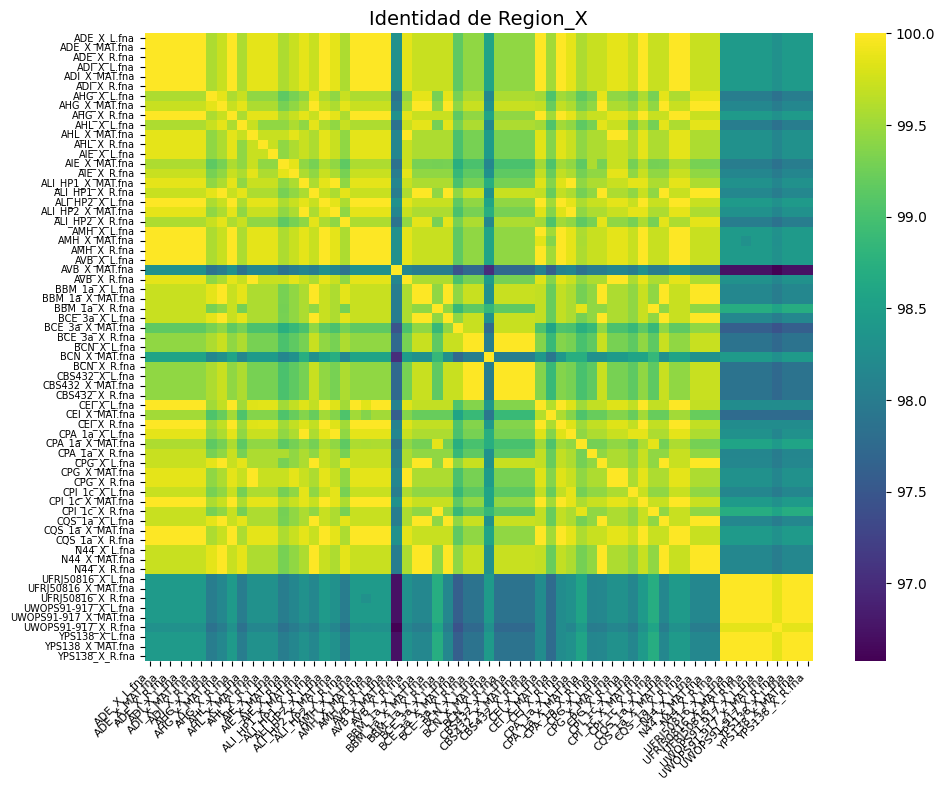

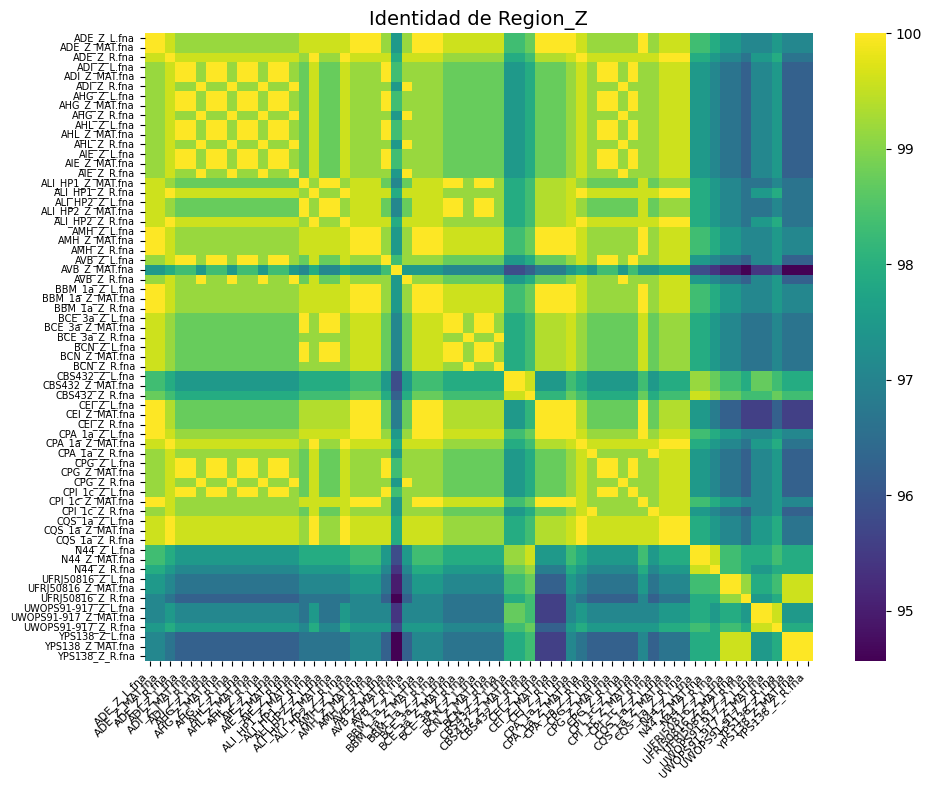

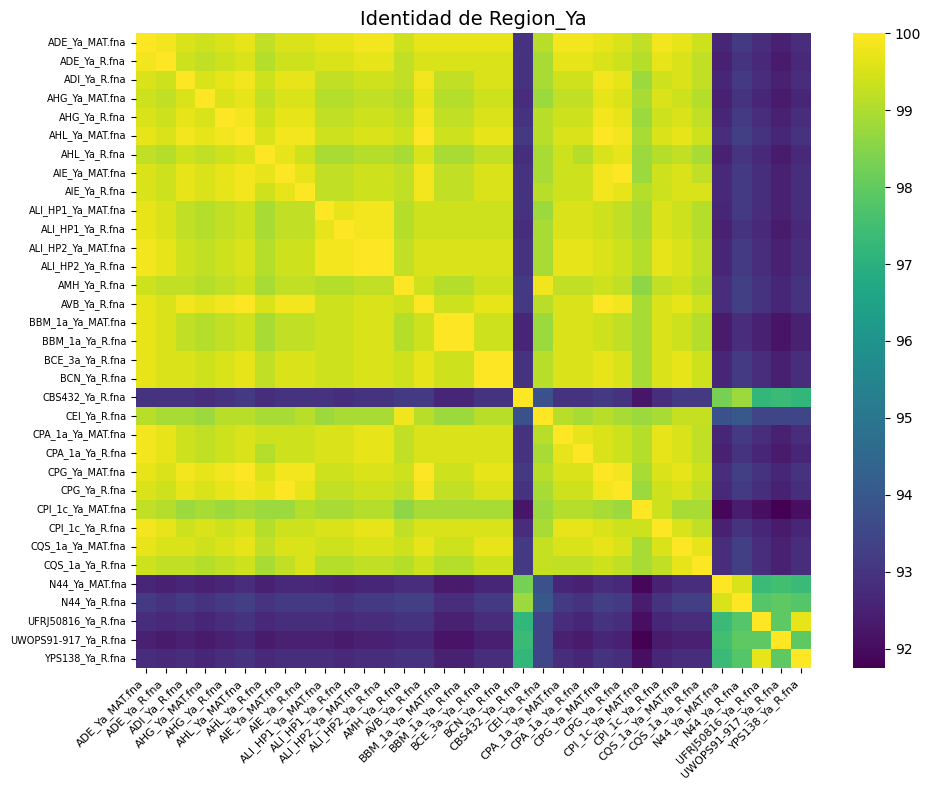

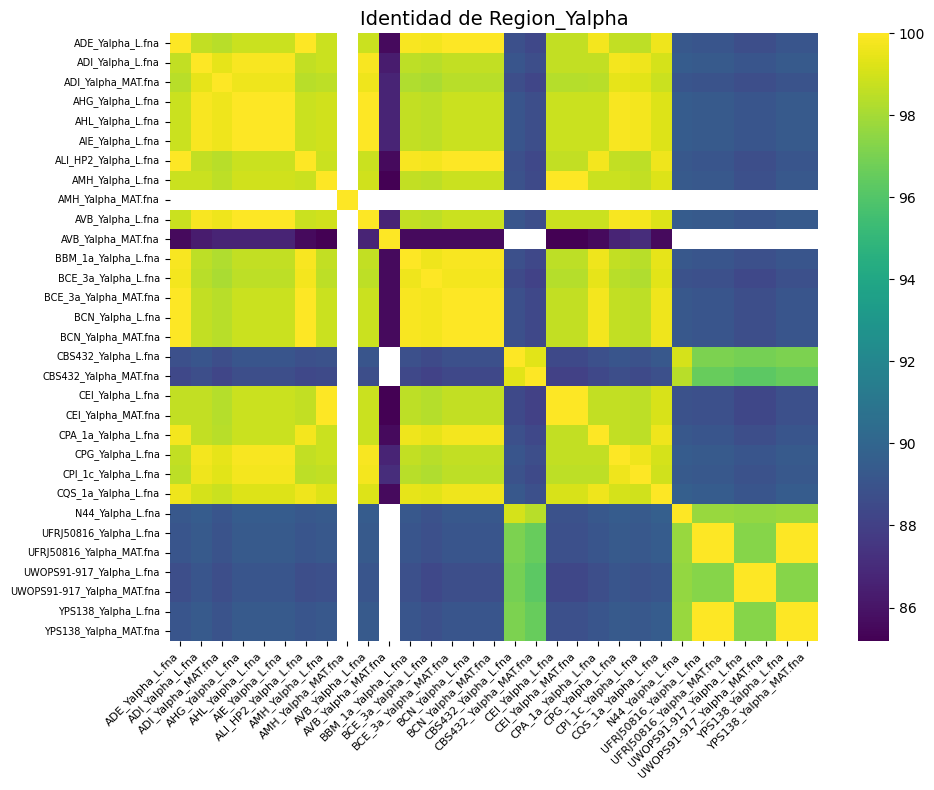

In [ ]:
archivo_excel = 'matriz_identidad_regiones.xlsx'
hojas = pd.ExcelFile(archivo_excel).sheet_names

os.makedirs('Images', exist_ok=True)

for hoja in hojas:
    # Leer la hoja de Excel con la primera columna como índice
    df = pd.read_excel(archivo_excel, sheet_name=hoja, index_col=0)

    # Filtrar solo las columnas numéricas
    df_numerico = df.select_dtypes(include=['number'])

    if df_numerico.empty:
        print(f'No hay datos numéricos en la hoja {hoja}.')
        continue

    plt.figure(figsize=(10, 8))

    # Crear el heatmap usando los nombres como etiquetas en el eje de las filas
    ax = sns.heatmap(df_numerico, annot=False, fmt='.2f', cmap="viridis",
                     yticklabels=df_numerico.index, xticklabels=df_numerico.columns)

    plt.title(f'Identidad de {hoja}', fontsize=14)  # Título con tamaño de fuente más pequeño

    # Ajustar el tamaño de las etiquetas de los ejes
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=8)  # Reducir tamaño de fuente en el eje x
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=7)  # Reducir tamaño de fuente en el eje y

    # Ajustar márgenes para que las etiquetas no se corten
    plt.tight_layout()

    # Guardar el heatmap como imagen
    plt.savefig(f'Images/heatmap_identidad_{hoja}.png')

    plt.show()  # Mostrar el heatmap


### Cobertura

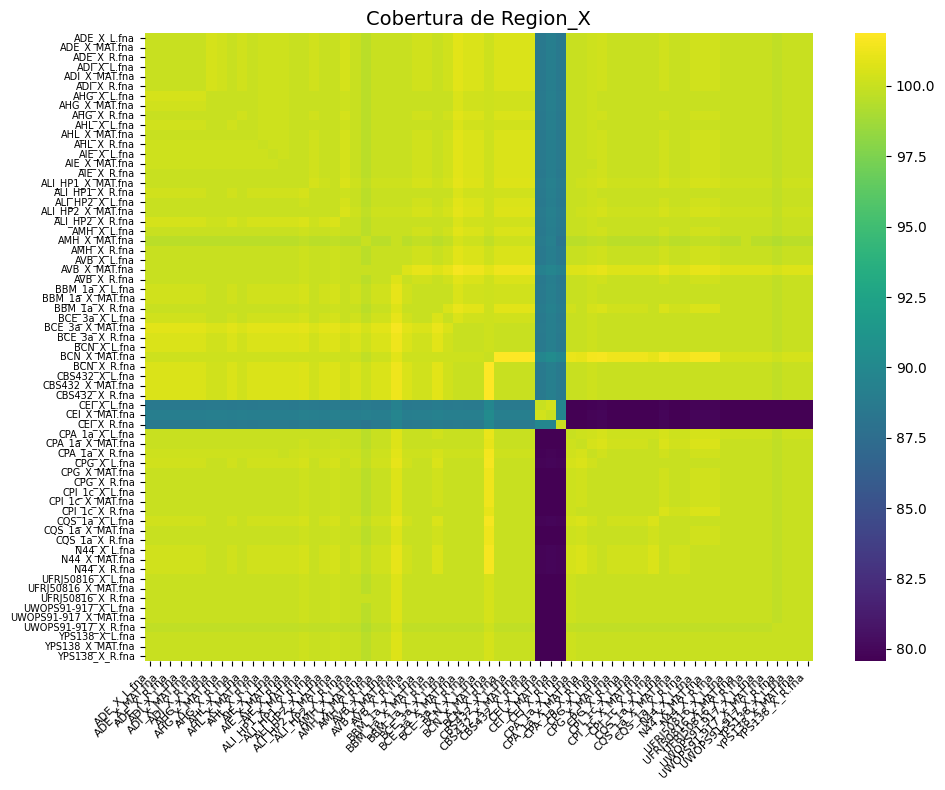

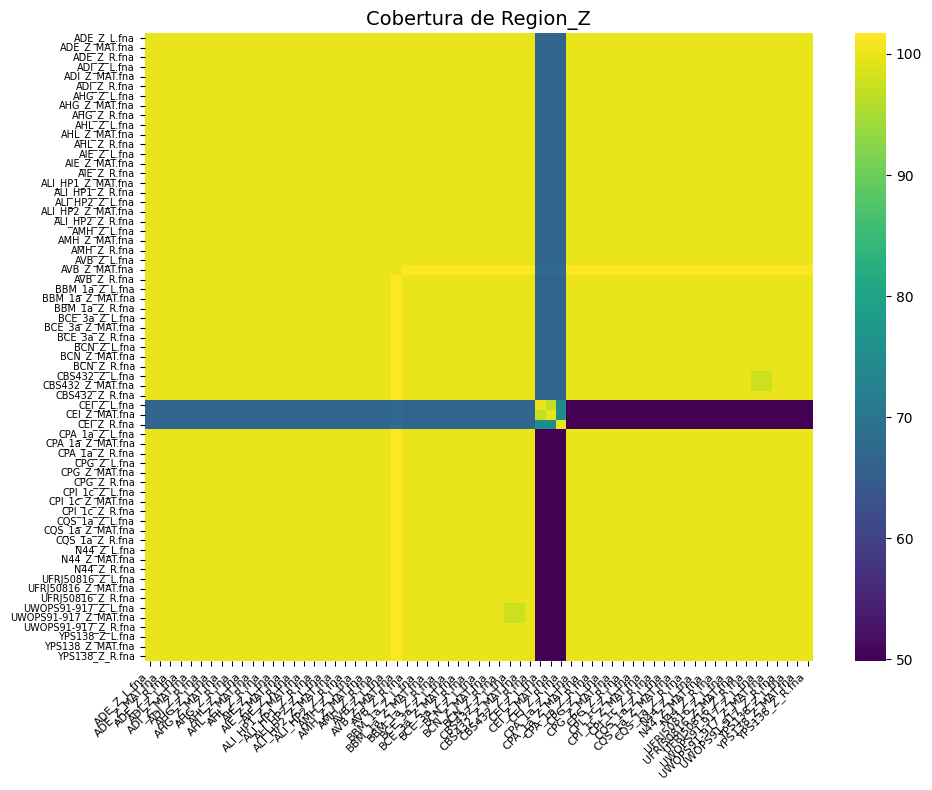

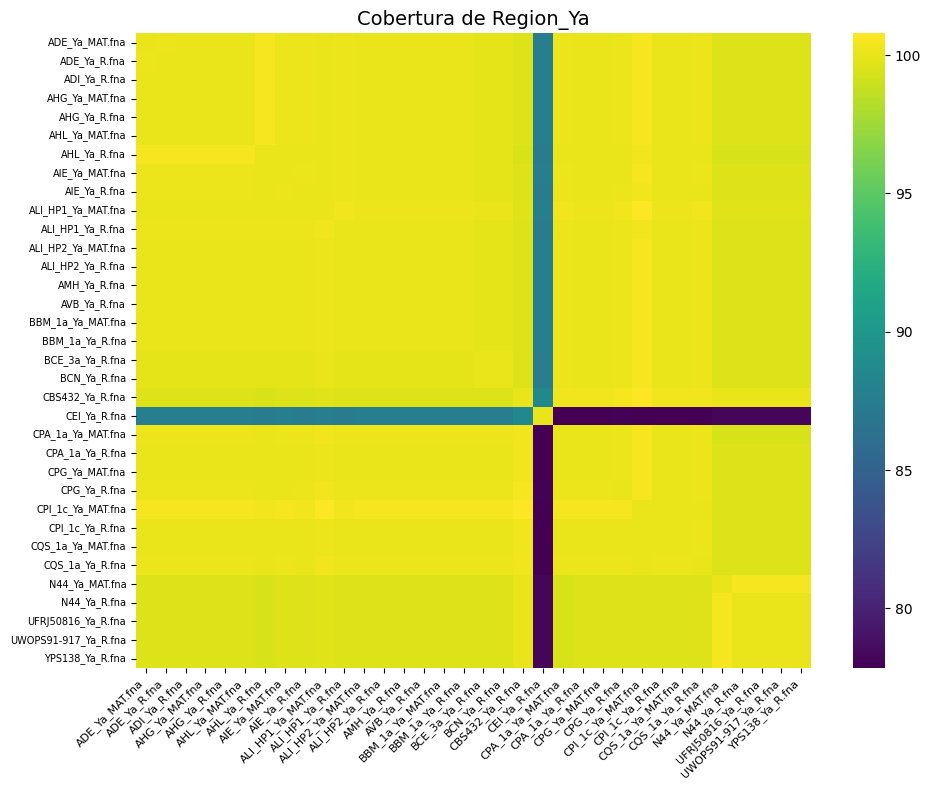

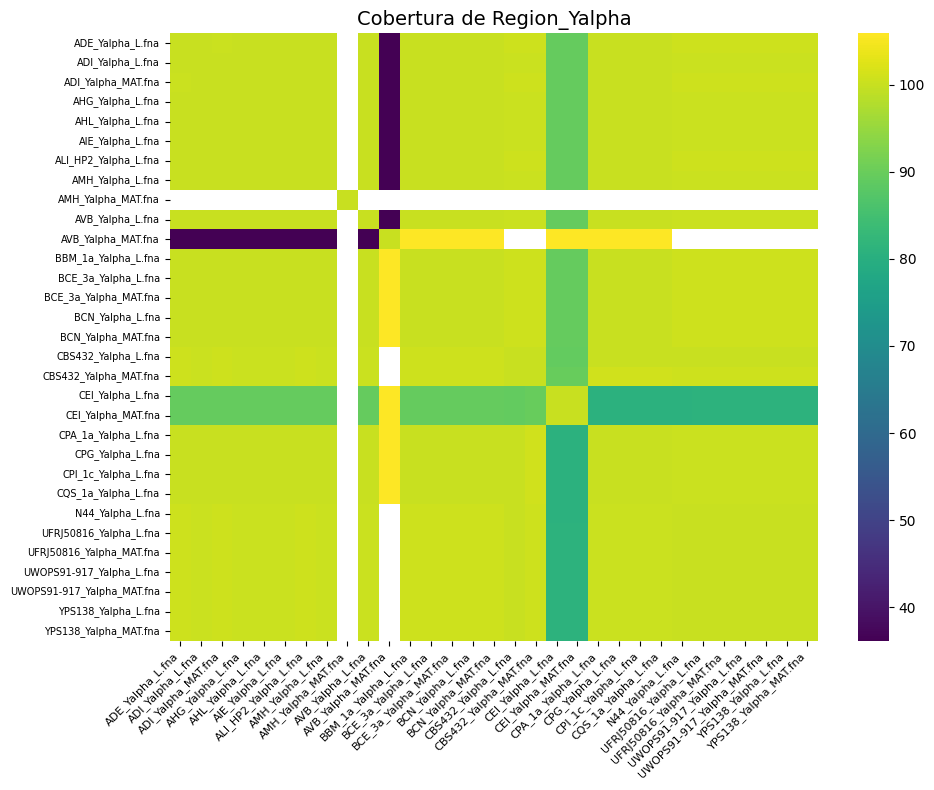

In [ ]:
archivo_excel = 'matriz_cobertura_regiones.xlsx'
hojas = pd.ExcelFile(archivo_excel).sheet_names

os.makedirs('Images', exist_ok=True)

for hoja in hojas:
    # Leer la hoja de Excel con la primera columna como índice
    df = pd.read_excel(archivo_excel, sheet_name=hoja, index_col=0)

    # Filtrar solo las columnas numéricas
    df_numerico = df.select_dtypes(include=['number'])

    if df_numerico.empty:
        print(f'No hay datos numéricos en la hoja {hoja}.')
        continue

    plt.figure(figsize=(10, 8))

    # Crear el heatmap usando los nombres como etiquetas en el eje de las filas
    ax = sns.heatmap(df_numerico, annot=False, fmt='.2f', cmap="viridis",
                     yticklabels=df_numerico.index, xticklabels=df_numerico.columns)

    plt.title(f'Cobertura de {hoja}', fontsize=14)  # Título con tamaño de fuente más pequeño

    # Ajustar el tamaño de las etiquetas de los ejes
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=8)  # Reducir tamaño de fuente en el eje x
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=7)  # Reducir tamaño de fuente en el eje y

    # Ajustar márgenes para que las etiquetas no se corten
    plt.tight_layout()

    # Guardar el heatmap como imagen
    plt.savefig(f'Images/heatmap_cobertura_{hoja}.png')

    plt.show()  # Mostrar el heatmap


## Heatmap con W y Z2

### Identidad

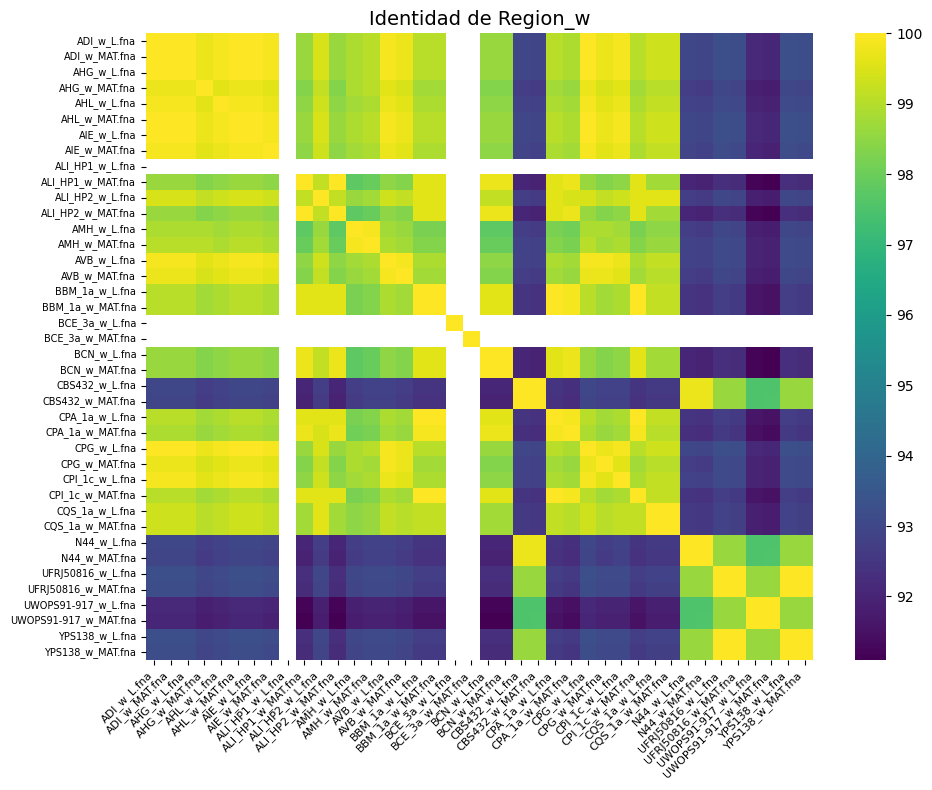

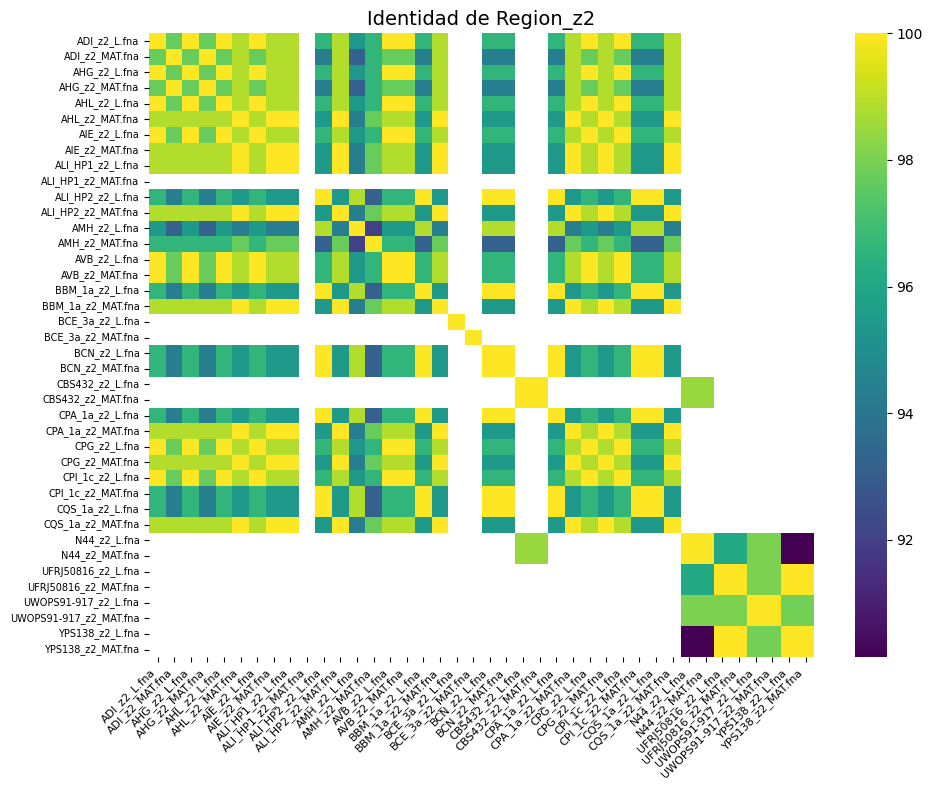

In [33]:
archivo_excel = 'matriz_identidad_regiones.xlsx'
hojas = pd.ExcelFile(archivo_excel).sheet_names

os.makedirs('Images', exist_ok=True)

for hoja in hojas:
    # Leer la hoja de Excel con la primera columna como índice
    df = pd.read_excel(archivo_excel, sheet_name=hoja, index_col=0)

    # Filtrar solo las columnas numéricas
    df_numerico = df.select_dtypes(include=['number'])

    if df_numerico.empty:
        print(f'No hay datos numéricos en la hoja {hoja}.')
        continue

    plt.figure(figsize=(10, 8))

    # Crear el heatmap usando los nombres como etiquetas en el eje de las filas
    ax = sns.heatmap(df_numerico, annot=False, fmt='.2f', cmap="viridis",
                     yticklabels=df_numerico.index, xticklabels=df_numerico.columns)

    plt.title(f'Identidad de {hoja}', fontsize=14)  # Título con tamaño de fuente más pequeño

    # Ajustar el tamaño de las etiquetas de los ejes
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=8)  # Reducir tamaño de fuente en el eje x
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=7)  # Reducir tamaño de fuente en el eje y

    # Ajustar márgenes para que las etiquetas no se corten
    plt.tight_layout()

    # Guardar el heatmap como imagen
    plt.savefig(f'Images/heatmap_identidad_{hoja}.png')

    plt.show()  # Mostrar el heatmap


### Cobertura

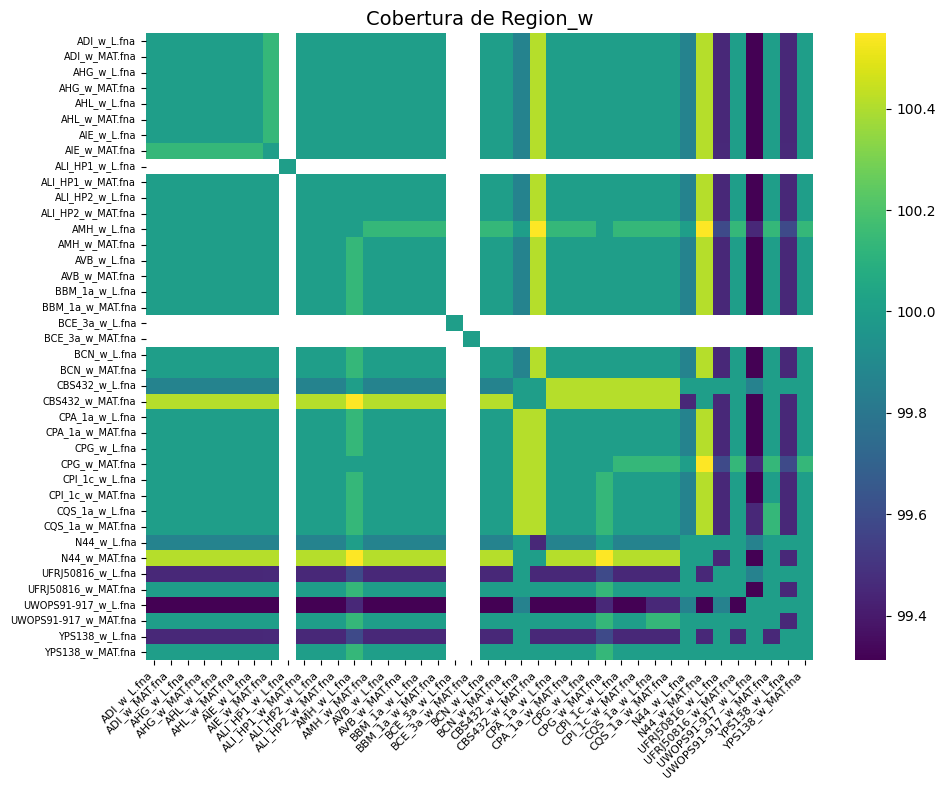

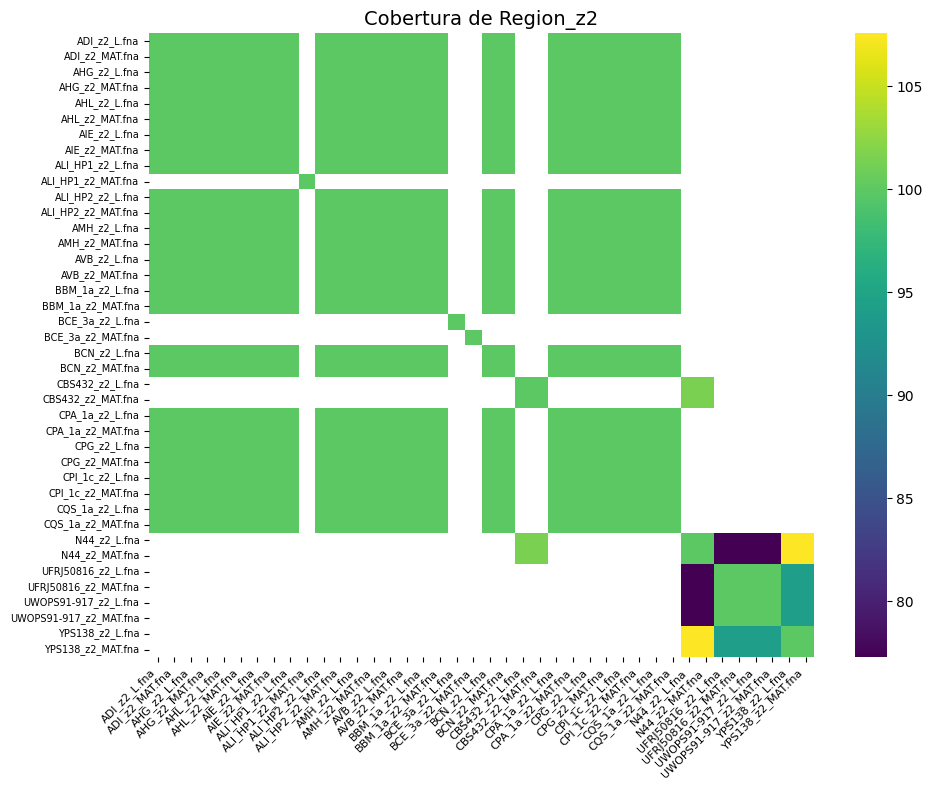

In [35]:
archivo_excel = 'matriz_cobertura_regiones.xlsx'
hojas = pd.ExcelFile(archivo_excel).sheet_names

os.makedirs('Images', exist_ok=True)

for hoja in hojas:
    # Leer la hoja de Excel con la primera columna como índice
    df = pd.read_excel(archivo_excel, sheet_name=hoja, index_col=0)

    # Filtrar solo las columnas numéricas
    df_numerico = df.select_dtypes(include=['number'])

    if df_numerico.empty:
        print(f'No hay datos numéricos en la hoja {hoja}.')
        continue

    plt.figure(figsize=(10, 8))

    # Crear el heatmap usando los nombres como etiquetas en el eje de las filas
    ax = sns.heatmap(df_numerico, annot=False, fmt='.2f', cmap="viridis",
                     yticklabels=df_numerico.index, xticklabels=df_numerico.columns)

    plt.title(f'Cobertura de {hoja}', fontsize=14)  # Título con tamaño de fuente más pequeño

    # Ajustar el tamaño de las etiquetas de los ejes
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=8)  # Reducir tamaño de fuente en el eje x
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=7)  # Reducir tamaño de fuente en el eje y

    # Ajustar márgenes para que las etiquetas no se corten
    plt.tight_layout()

    # Guardar el heatmap como imagen
    plt.savefig(f'Images/heatmap_cobertura_{hoja}.png')

    plt.show()  # Mostrar el heatmap


## Comprimir

In [36]:
# comprimir carpeta imagenes

!zip -r Images.zip Images


  adding: Images/ (stored 0%)
  adding: Images/heatmap_identidad_Region_z2.png (deflated 15%)
  adding: Images/heatmap_cobertura_Region_w.png (deflated 16%)
  adding: Images/heatmap_identidad_Region_w.png (deflated 15%)
  adding: Images/heatmap_cobertura_Region_z2.png (deflated 16%)


In [37]:
# comprimir carpeta CHR3, genes y regiones

import zipfile
import os

def compress_folder(folder_path, output_zip_path):
  """Comprime una carpeta en un archivo ZIP.

  Args:
    folder_path: Ruta de la carpeta a comprimir.
    output_zip_path: Ruta del archivo ZIP de salida.
  """
  with zipfile.ZipFile(output_zip_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for root, _, files in os.walk(folder_path):
      for file in files:
        file_path = os.path.join(root, file)
        zipf.write(file_path, os.path.relpath(file_path, folder_path))


# Ejemplo de uso
#compress_folder('/content/CORRECTO/CHR3', '/content/CHR3.zip')
#compress_folder('/content/CORRECTO/genes', '/content/genes.zip')
compress_folder('/content/regiones', '/content/regiones.zip')


## Archvivos Fasta

### X

In [ ]:
# Carpeta que contiene los archivos
carpeta_fna = '/content/CORRECTO/regiones/X'  # Cambia esto a la ruta de tu carpeta
archivo_fasta = 'x_sequences.fasta'  # Nombre del archivo de salida

# Crear o abrir el archivo fasta para escritura
with open(archivo_fasta, 'w') as outfile:
    for filename in os.listdir(carpeta_fna):
        file_path = os.path.join(carpeta_fna, filename)

        # Verificar que sea un archivo y no un directorio
        if os.path.isfile(file_path):
            file_base_name = os.path.splitext(filename)[0]  # Obtener el nombre base del archivo sin extensión

            with open(file_path, 'r') as infile:
                for i, line in enumerate(infile):
                    if i == 0 and line.startswith('>'):
                        # Reemplazar toda la línea por el nombre del archivo
                        line = f">{file_base_name}\n"
                    outfile.write(line)
                outfile.write('\n')  # Añadir una nueva línea entre archivos

print(f'Se han combinado los archivos en {archivo_fasta}.')


Se han combinado los archivos en x_sequences.fasta.


In [ ]:
import re

archivo_fasta = 'x_sequences.fasta'
archivo_salida = 'x_sequences_correct.fasta'

# Lista de cepas exactas que deben ser marcadas como 'S.p'
cepas_sp = ['CBS432', 'N44', 'YPS138', 'UWOPS91-917.1']

with open(archivo_fasta, 'r') as infile, open(archivo_salida, 'w') as outfile:
    for line in infile:
        if line.startswith('>'):
            # Buscar el nombre de la cepa al principio de la línea después de '>'
            match = re.search(r'^>(\S+)', line)
            if match:
                strain_name = match.group(1).split('_')[0]  # Tomar solo la parte antes de '_'
                if strain_name in cepas_sp:
                    outfile.write(line.replace('>', '>S.p '))
                else:
                    outfile.write(line.replace('>', '>S.c '))
            else:
                outfile.write(line)  # Escribir la línea tal cual si no hay coincidencia
        else:
            outfile.write(line)

print(f'Se ha modificado el archivo en {archivo_salida}.')


Se ha modificado el archivo en x_sequences_correct.fasta.


### Z

In [ ]:
# Carpeta que contiene los archivos
carpeta_fna = '/content/CORRECTO/regiones/Z'  # Cambia esto a la ruta de tu carpeta
archivo_fasta = 'z_sequences.fasta'  # Nombre del archivo de salida

# Crear o abrir el archivo fasta para escritura
with open(archivo_fasta, 'w') as outfile:
    for filename in os.listdir(carpeta_fna):
        file_path = os.path.join(carpeta_fna, filename)

        # Verificar que sea un archivo y no un directorio
        if os.path.isfile(file_path):
            file_base_name = os.path.splitext(filename)[0]  # Obtener el nombre base del archivo sin extensión

            with open(file_path, 'r') as infile:
                for i, line in enumerate(infile):
                    if i == 0 and line.startswith('>'):
                        # Reemplazar toda la línea por el nombre del archivo
                        line = f">{file_base_name}\n"
                    outfile.write(line)
                outfile.write('\n')  # Añadir una nueva línea entre archivos

print(f'Se han combinado los archivos en {archivo_fasta}.')


Se han combinado los archivos en z_sequences.fasta.


In [ ]:
import re

archivo_fasta = 'z_sequences.fasta'
archivo_salida = 'z_sequences_correct.fasta'

# Lista de cepas exactas que deben ser marcadas como 'S.p'
cepas_sp = ['CBS432', 'N44', 'YPS138', 'UWOPS91-917.1']

with open(archivo_fasta, 'r') as infile, open(archivo_salida, 'w') as outfile:
    for line in infile:
        if line.startswith('>'):
            # Buscar el nombre de la cepa al principio de la línea después de '>'
            match = re.search(r'^>(\S+)', line)
            if match:
                strain_name = match.group(1).split('_')[0]  # Tomar solo la parte antes de '_'
                if strain_name in cepas_sp:
                    outfile.write(line.replace('>', '>S.p '))
                else:
                    outfile.write(line.replace('>', '>S.c '))
            else:
                outfile.write(line)  # Escribir la línea tal cual si no hay coincidencia
        else:
            outfile.write(line)

print(f'Se ha modificado el archivo en {archivo_salida}.')


Se ha modificado el archivo en z_sequences_correct.fasta.


### Ya

In [ ]:
# Carpeta que contiene los archivos
carpeta_fna = '/content/CORRECTO/regiones/Ya'  # Cambia esto a la ruta de tu carpeta
archivo_fasta = 'ya_sequences.fasta'  # Nombre del archivo de salida

# Crear o abrir el archivo fasta para escritura
with open(archivo_fasta, 'w') as outfile:
    for filename in os.listdir(carpeta_fna):
        file_path = os.path.join(carpeta_fna, filename)

        # Verificar que sea un archivo y no un directorio
        if os.path.isfile(file_path):
            file_base_name = os.path.splitext(filename)[0]  # Obtener el nombre base del archivo sin extensión

            with open(file_path, 'r') as infile:
                for i, line in enumerate(infile):
                    if i == 0 and line.startswith('>'):
                        # Reemplazar toda la línea por el nombre del archivo
                        line = f">{file_base_name}\n"
                    outfile.write(line)
                outfile.write('\n')  # Añadir una nueva línea entre archivos

print(f'Se han combinado los archivos en {archivo_fasta}.')


Se han combinado los archivos en ya_sequences.fasta.


In [ ]:
import re

archivo_fasta = 'ya_sequences.fasta'
archivo_salida = 'ya_sequences_correct.fasta'

# Lista de cepas exactas que deben ser marcadas como 'S.p'
cepas_sp = ['CBS432', 'N44', 'YPS138', 'UWOPS91-917.1']

with open(archivo_fasta, 'r') as infile, open(archivo_salida, 'w') as outfile:
    for line in infile:
        if line.startswith('>'):
            # Buscar el nombre de la cepa al principio de la línea después de '>'
            match = re.search(r'^>(\S+)', line)
            if match:
                strain_name = match.group(1).split('_')[0]  # Tomar solo la parte antes de '_'
                if strain_name in cepas_sp:
                    outfile.write(line.replace('>', '>S.p '))
                else:
                    outfile.write(line.replace('>', '>S.c '))
            else:
                outfile.write(line)  # Escribir la línea tal cual si no hay coincidencia
        else:
            outfile.write(line)

print(f'Se ha modificado el archivo en {archivo_salida}.')


Se ha modificado el archivo en ya_sequences_correct.fasta.


### Yalpha

In [ ]:
# Carpeta que contiene los archivos
carpeta_fna = '/content/CORRECTO/regiones/Yalpha'  # Cambia esto a la ruta de tu carpeta
archivo_fasta = 'yalpha_sequences.fasta'  # Nombre del archivo de salida

# Crear o abrir el archivo fasta para escritura
with open(archivo_fasta, 'w') as outfile:
    for filename in os.listdir(carpeta_fna):
        file_path = os.path.join(carpeta_fna, filename)

        # Verificar que sea un archivo y no un directorio
        if os.path.isfile(file_path):
            file_base_name = os.path.splitext(filename)[0]  # Obtener el nombre base del archivo sin extensión

            with open(file_path, 'r') as infile:
                for i, line in enumerate(infile):
                    if i == 0 and line.startswith('>'):
                        # Reemplazar toda la línea por el nombre del archivo
                        line = f">{file_base_name}\n"
                    outfile.write(line)
                outfile.write('\n')  # Añadir una nueva línea entre archivos

print(f'Se han combinado los archivos en {archivo_fasta}.')


Se han combinado los archivos en yalpha_sequences.fasta.


In [ ]:
import re

archivo_fasta = 'yalpha_sequences.fasta'
archivo_salida = 'yalpha_sequences_correct.fasta'

# Lista de cepas exactas que deben ser marcadas como 'S.p'
cepas_sp = ['CBS432', 'N44', 'YPS138', 'UWOPS91-917.1']

with open(archivo_fasta, 'r') as infile, open(archivo_salida, 'w') as outfile:
    for line in infile:
        if line.startswith('>'):
            # Buscar el nombre de la cepa al principio de la línea después de '>'
            match = re.search(r'^>(\S+)', line)
            if match:
                strain_name = match.group(1).split('_')[0]  # Tomar solo la parte antes de '_'
                if strain_name in cepas_sp:
                    outfile.write(line.replace('>', '>S.p '))
                else:
                    outfile.write(line.replace('>', '>S.c '))
            else:
                outfile.write(line)  # Escribir la línea tal cual si no hay coincidencia
        else:
            outfile.write(line)

print(f'Se ha modificado el archivo en {archivo_salida}.')


Se ha modificado el archivo en yalpha_sequences_correct.fasta.
